# 04 · K-Means Is Hard EM

K-Means and Gaussian-mixture EM are usually taught as two different algorithms. They
are not. **K-Means is the mixture loop with the soft responsibilities forced to
all-or-nothing** (each point assigned entirely to its single nearest centroid),
spherical equal covariance, and equal weights.

Take the EM loop from notebook 03, replace the soft responsibilities with a hard
`argmax`, and out comes K-Means — assignment for assignment. This notebook shows the
equivalence, then shows exactly what the *soft*, *elliptical* version buys you back.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def _repo_root() -> Path:
    here = Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").exists():
            return cand
    return here


ROOT = _repo_root()
FIG_DIR = ROOT / "outputs" / "figures"
DATA_DIR = ROOT / "outputs" / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)


def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def savefig(fig, name):
    """Save a matplotlib figure as outputs/figures/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"figure -> {path.relative_to(ROOT)}")
    return path


def savejson(name, obj):
    """Save textual/numerical content as outputs/data/<name>.json."""
    path = DATA_DIR / f"{name}.json"
    path.write_text(json.dumps(_jsonable(obj), indent=2))
    print(f"data   -> {path.relative_to(ROOT)}")
    return path


plt.rcParams["figure.figsize"] = (7, 4.2)
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)


## The equivalence, on well-separated blobs

We run two things on the same data with the same initialization:
- `KMeansEM` — a standalone Lloyd's K-Means.
- `kmeans_as_hard_em` — the **GMM loop** run in hard / spherical / tied / equal-weight mode.

They produce the same partition.


same partition: True
figure -> outputs/figures/nb04_kmeans_vs_hardem.png
data   -> outputs/data/nb04_equivalence.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb04_equivalence.json')

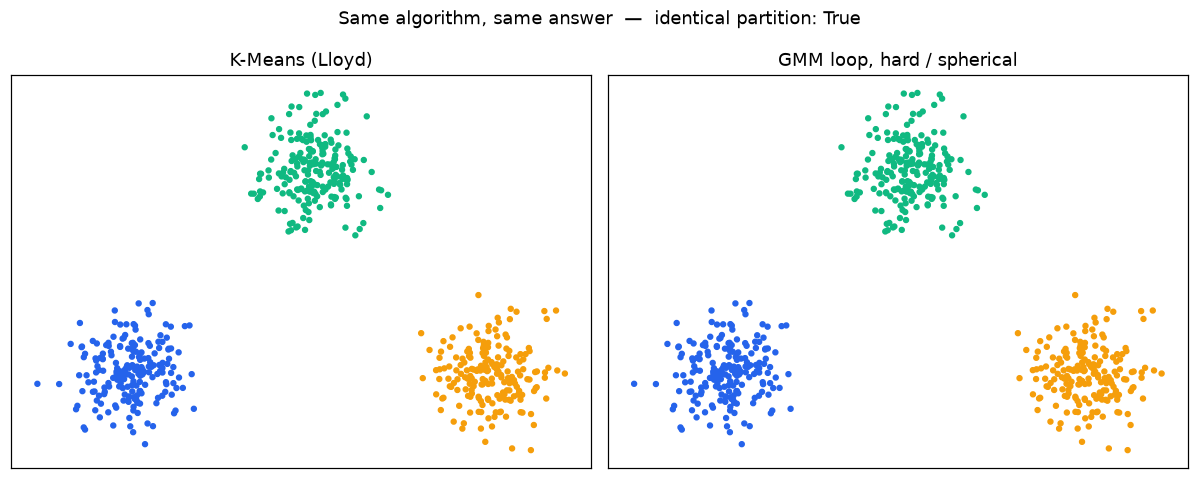

In [2]:
from src.datasets.mixtures import make_blobs
from src.em.kmeans import KMeansEM, kmeans_as_hard_em
from src.evaluation.recovery import clustering_accuracy, same_partition

X, _, _ = make_blobs(600, [[-6, 0], [6, 0], [0, 7]], cluster_std=1.0, seed=7)

km = KMeansEM(3, n_init=1, random_state=0).fit(X)
hard_labels = kmeans_as_hard_em(X, 3, random_state=0)

agree = same_partition(km.labels_, hard_labels)
print("same partition:", agree)

COLORS = np.array(["#2563eb", "#f59e0b", "#10b981"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(X[:, 0], X[:, 1], s=10, c=COLORS[km.labels_]); axes[0].set_title("K-Means (Lloyd)")
axes[1].scatter(X[:, 0], X[:, 1], s=10, c=COLORS[hard_labels]); axes[1].set_title("GMM loop, hard / spherical")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Same algorithm, same answer  —  identical partition: {agree}")
fig.tight_layout()
savefig(fig, "nb04_kmeans_vs_hardem")

savejson("nb04_equivalence", {
    "same_partition": bool(agree),
    "agreement_fraction": clustering_accuracy(km.labels_, hard_labels),
    "kmeans_inertia": km.inertia_,
})


## What soft + elliptical buys back

K-Means assumes round, equal-size clusters and commits to a hard split. When the real
groups have **different spreads / weights** or **elliptical, correlated** shapes, that
assumption misclassifies the overlap. A full-covariance Gaussian mixture, weighting each
point softly by how well each component explains it, recovers the groups K-Means breaks.


accuracy vs truth   K-Means=0.795   GMM=0.961


figure -> outputs/figures/nb04_soft_vs_hard.png
data   -> outputs/data/nb04_soft_vs_hard.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb04_soft_vs_hard.json')

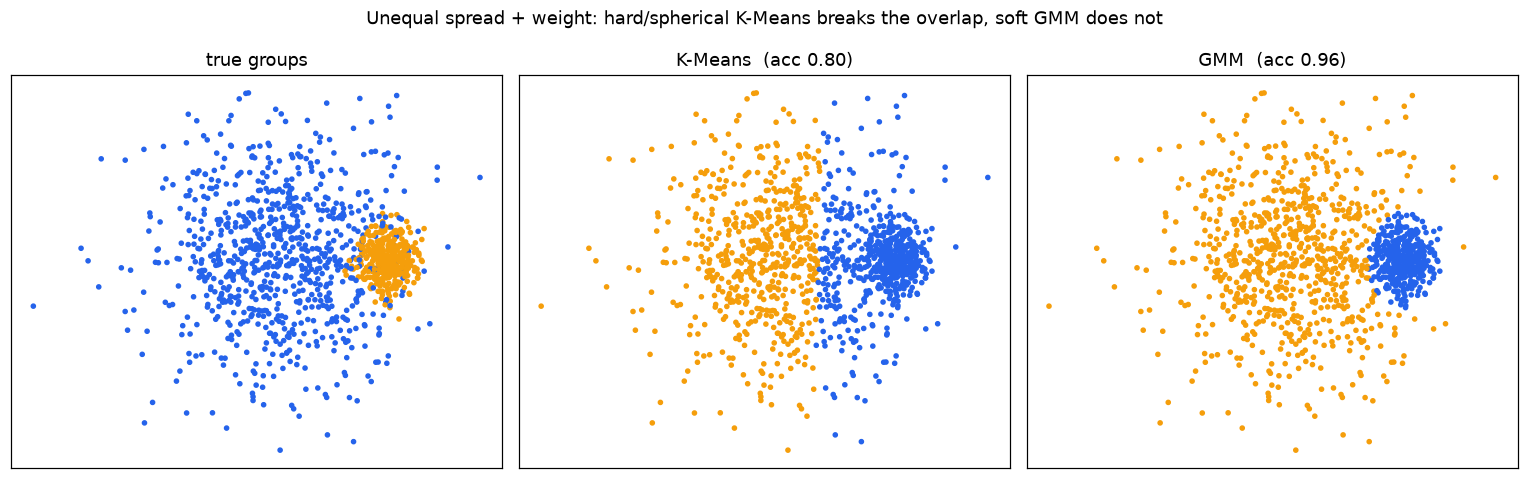

In [3]:
from src.datasets.mixtures import make_gaussian_mixture
from src.em.gmm import GaussianMixtureEM

# one broad cluster and one tight cluster, overlapping, with unequal weights
means = [[-1.0, 0.0], [3.0, 0.0]]
covs = [[[5.0, 0.0], [0.0, 5.0]], [[0.35, 0.0], [0.0, 0.35]]]
Xe, ytrue, _ = make_gaussian_mixture(1200, [0.65, 0.35], means, covs, seed=4)

km_e = KMeansEM(2, n_init=10, random_state=0).fit(Xe)
gmm_e = GaussianMixtureEM(2, n_init=10, random_state=0).fit(Xe)

acc_km = clustering_accuracy(ytrue, km_e.labels_)
acc_gmm = clustering_accuracy(ytrue, gmm_e.labels_)
print(f"accuracy vs truth   K-Means={acc_km:.3f}   GMM={acc_gmm:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
axes[0].scatter(Xe[:, 0], Xe[:, 1], s=7, c=COLORS[ytrue]); axes[0].set_title("true groups")
axes[1].scatter(Xe[:, 0], Xe[:, 1], s=7, c=COLORS[km_e.labels_])
axes[1].set_title(f"K-Means  (acc {acc_km:.2f})")
axes[2].scatter(Xe[:, 0], Xe[:, 1], s=7, c=COLORS[gmm_e.labels_])
axes[2].set_title(f"GMM  (acc {acc_gmm:.2f})")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Unequal spread + weight: hard/spherical K-Means breaks the overlap, soft GMM does not")
fig.tight_layout()
savefig(fig, "nb04_soft_vs_hard")

savejson("nb04_soft_vs_hard", {
    "planted": {"weights": [0.65, 0.35], "means": means, "covariances": covs},
    "accuracy_kmeans": acc_km,
    "accuracy_gmm": acc_gmm,
})


## Soft membership, made visible

The only real difference at the assignment step is softness. Coloring points by the
*responsibility* of one component shows GMM's graded membership near the boundary —
the information K-Means throws away when it rounds every responsibility to 0 or 1.


figure -> outputs/figures/nb04_soft_membership.png


PosixPath('/workspaces/expectation_maximization_101/outputs/figures/nb04_soft_membership.png')

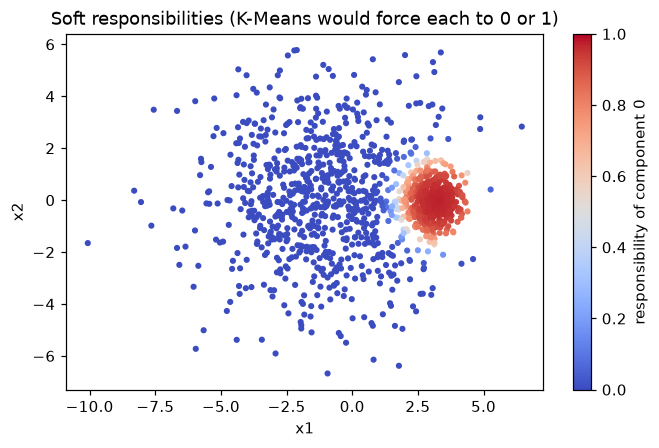

In [4]:
proba = gmm_e.predict_proba(Xe)[:, 0]
fig, ax = plt.subplots()
sc = ax.scatter(Xe[:, 0], Xe[:, 1], s=9, c=proba, cmap="coolwarm", vmin=0, vmax=1)
fig.colorbar(sc, ax=ax, label="responsibility of component 0")
ax.set_title("Soft responsibilities (K-Means would force each to 0 or 1)")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
savefig(fig, "nb04_soft_membership")


## Takeaway

One loop, one knob. Turn softness off and you get K-Means (fast, assumes round equal
clusters); leave it on with full covariances and you get a Gaussian mixture (handles
elliptical, unequal groups). Two algorithms you learned separately are the same algorithm
at different settings — which is exactly why GMM edged out K-Means in the clustering arena.

**Next:** `05_missing_data` — point the same loop at missing values instead of hidden labels.


In [5]:
savejson("nb04_narrative", {
    "title": "K-Means Is Hard EM",
    "claim": "K-Means = EM with hard (argmax) responsibilities, spherical equal covariance, equal weights.",
    "what_soft_buys": "Soft membership and full covariance recover elliptical / unequal-weight groups K-Means breaks.",
    "figures": {
        "nb04_kmeans_vs_hardem": "K-Means and the hard-EM GMM loop produce the identical partition.",
        "nb04_soft_vs_hard": "On unequal-spread clusters, GMM beats K-Means.",
        "nb04_soft_membership": "Graded responsibilities near the boundary.",
    },
})


data   -> outputs/data/nb04_narrative.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb04_narrative.json')